# The queue and what I'd recommend

Every number here comes from `reports/results.json`. `python -m bleedtracker reproduce` builds that file from the warehouse and checks it against my original results.

In [1]:
import pandas as pd
from IPython.display import Image

from bleedtracker.results import RESULTS_FILE, load_results

results = load_results()
FIGURES = RESULTS_FILE.parent / "figures"

## The queue

The editor gets 50 slots from the rule. Ten shadow items from the forest ride along for whoever owns the model. The editor doesn't review those.

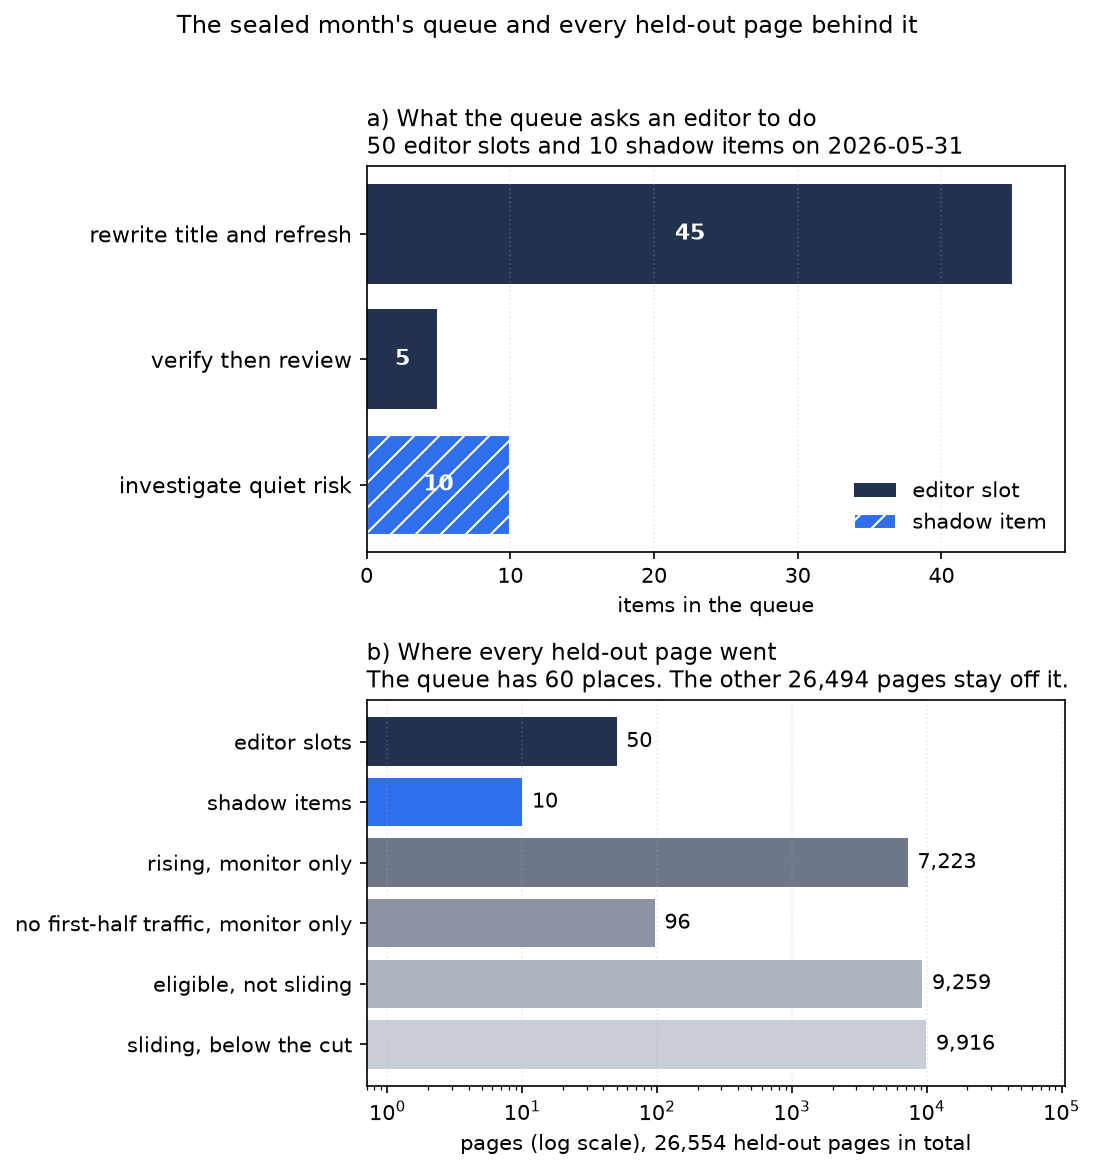

In [2]:
Image(filename=FIGURES / "figure_3_queue.png")

In [3]:
from bleedtracker.gates import PLAYBOOK

pd.set_option("display.max_colwidth", None)
PLAYBOOK.set_index("reason_code")[["action", "archetype", "guardrail"]]

,action,archetype,guardrail
reason_code,,,
slipping_and_underclicking,rewrite_title_and_refresh,A visible page that is losing clicks it already earns.,A rewrite can't fix a page that answers the wrong question. Check the search queries first.
slipping_reachable_page,refresh_now,"A page an edit could still lift, sliding inside the month.",A slide can be seasonal. Check last year and the client's calendar.
slipping_deep_page,expand_or_consolidate,"A page past position 20, sliding, unlikely to come back with an edit.",Merging can't be undone. Never merge without a person who owns the page.
quiet_risk_model_only,investigate_quiet_risk,A flat page the rule can't score that the forest ranks high.,The forest gives no reason. A person supplies one or the item is dropped.
measurement_suspicion,verify_then_review,"One day, or a short live window, carries the month.",Check the tracking and any campaign before touching the content.
durable_riser,monitor_only,A page that was rising when the month closed.,Never acted on. Rising pages declined less often than the base rate.
new_or_no_first_half_traffic,monitor_only,A page with no first-half traffic. Its momentum is filled in.,Never acted on. Its slide signal is made up.
holding_steady,monitor,A page that isn't sliding and that the shadow queue didn't pick.,The queue isn't a to-do list for every page.


In the sealed month, 45 of the 50 slots ask for a title rewrite and a refresh. The other 5 ask to verify first. On those pages one day, or a short live window, carries the month. The 50 slots come from 3 clients. 49 of the 50 pages declined. 7 of the 10 shadow items did.

The gates kept 7,223 rising pages and 96 pages with no first-half traffic out of the queue.

Every item comes with four questions for the editor.

1. Is this a season or a one-off? Check the same weeks last year and the client's calendar.
2. Is the page still about what people search for? A rewrite can't fix a page that answers the wrong question.
3. Is the client changing something right now, like a migration, a redesign or the tracking?
4. Will I be able to tell next month whether this helped? If not, wait.

## Limitations

**1. The headline is mostly one client.** In the sealed held-out pool, the largest client holds 90.2% of the pages. Only 8 of the 9 held-out clients had a scorable page in May 2026. A precision@50 on this pool is mostly about one site.

**2. Precision isn't comparable across months.**

In [4]:
pd.DataFrame(results["limitations"]["month_table"]).set_index("pair")

,pages,slice_base_rate,held_out_base_rate,median_next_over_now,share_of_pages_that_grew
pair,,,,,
2026-01 to 2026-02,63909,0.2512,0.2358,1.1385,0.5967
2026-02 to 2026-03,72745,0.2290,0.1940,1.1875,0.6360
2026-03 to 2026-04,85453,0.5378,0.4936,0.7561,0.3185
2026-04 to 2026-05,85518,0.5377,0.3880,0.7552,0.3071
2026-05 to 2026-06,82570,0.7027,0.7362,0.5590,0.1919


The held-out base rate ran 23.6%, 19.4%, 49.4%, 38.8% and 73.6%. The median page's next-month ratio fell from 1.14 to 0.56. The share of pages that grew fell from 60% to 19%. In this panel, June 2026 was a month when most pages fell.

**3. The metric saturates at a high base rate.** Fifty random pages score 0.736 in the sealed month. The forest on its five features and both leaked forests score 1.00. Only AUC tells them apart. I wouldn't publish precision@50 on its own.

**4. This is triage.** The 50 slots cover 0.25% of the 19,549 declining pages in the sealed held-out pool. They hold 2.3% of the impressions those pages lost.

**5. One feature carries most of the signal.**

In [5]:
worth = results["feature_worth"]
pd.DataFrame({name: month["ablation_auc"] for name, month in worth.items()}).rename_axis("AUC")

,open,sealed
AUC,,
without_log_impressions,0.7183,0.6871
without_active_days,0.7307,0.6936
without_position,0.6949,0.6958
without_ctr,0.7101,0.6599
without_momentum,0.6058,0.6268
all_five,0.7162,0.6926


On the sealed month, the forest's AUC drops by 0.066 without momentum. It drops by 0.033 without CTR and by 0.006 without impressions. Leaving out position or active days raises it a little. Momentum alone reaches a precision@50 of 0.913.

**6. The signal sees slides already under way.** It's weak at pages that look fine and then drop.

In [6]:
pd.DataFrame(results["limitations"]["biggest_bleeds"], index=range(1, 6)).rename_axis("bleed")

,momentum,rule_rank,forest_rank
bleed,,,
1,0.449,268,1010
2,0.855,19670,11054
3,0.981,19820,19831
4,1.241,13366,13710
5,0.967,10018,19983


The biggest bleed in the sealed held-out pool was already sliding, at momentum 0.449. The rule ranked it 268th and the forest 1,010th. Both left it out of the queue. The next four had momentum between 0.855 and 1.241 when May closed. The rule sees no slide above 0.8. The rule ranked them between 10,018th and 19,820th. The forest ranked them between 11,054th and 19,983rd.

The rule's one wrong pick in its 50 was sliding hard inside May. It didn't decline in June. Nothing known on 31 May tells a page in the middle of a fall from one about to recover.

**7. Staleness is out of reach.** The content table is a snapshot from 3 July 2026. 51.1% of the scored pages carry an update date after the decision. FlyRank's stale flag fires on 10 of 82,570 pages. A rule like "skip pages optimised in the last 30 days" needs a dated history.

**8. The clients are survivors.** The release has 104 clients. 40 have search history from before 2026. 24 have a scorable page in the sealed month. The results describe established clients with steady demand. A new client can't be tested here.

**9. The forest isn't calibrated.** The sealed deployment trains where 60.2% of pages decline. It's judged where 73.6% do. The queue ships an order and a percentile. It never ships a probability.

**10. Nothing here is causal or a forecast.** No page was changed to see what happened. There's no control group. Nothing here says anything about how a search engine ranks pages. The panel ends on 30 June 2026. No result has been checked on a later month.

## What I'd recommend, in order

**1. Ship the frozen rule as the 50-slot monthly queue.** Its precision@50 was 0.88, 0.90, 0.96 and 0.98 across four forward deployments on held-out clients. It cleared each month's base rate by 68.6, 40.6, 57.2 and 24.4 points. In the sealed month it also beat the 95th percentile of 200 random queues. It has no fitted weights. An editor can argue with every item. Confidence is high.

**2. Report the margin over the month's base rate next to every precision.** Precision rose from 0.96 to 0.98 between the last two deployments. The margin fell from 57.2 to 24.4 points. A dashboard showing 0.98 as progress would be showing the calendar. Confidence is high. This is arithmetic.

**3. Keep the forest in shadow.** The forest minus the rule ran −10, +8, −2 and +2 points. The mean is −0.5. The interval runs from −6.0 to +5.0. Ten forest slots scored 0.92 against 0.98 in the sealed month. The promotion rule declined to promote it. Its shadow queue beat its own pool in two months and lost in two. Confidence is medium. Keep measuring it.

**4. Fix the two calendar-shaped features before tuning anything.** `active_days` tops out at each month's own length. `momentum` splits a 31-day month 16/15. A flat page then scores about 6% low. Measuring both per day removes the problem. Confidence is high.

**5. Widen the drift alarm to compare each month with the one before.** On the sealed release the written alarm read 0.146 and stayed quiet. Month over month, `position` reached 0.4224. I found this by running my own rule as written. Confidence is high.

**6. Ask the data team for a dated update history.** 51.1% of the scored pages carry an update date after the decision. The stale flag fires on 10 pages. A dated history would allow a staleness signal. It would also allow a rule that never queues a page someone just optimised. Confidence is high. This is a data request.

**7. Decide between one queue and one queue per account.** Then measure the one that ships. With five pages per client, the rule falls from 0.98 to 0.825 and the forest to 0.775. One client holds 90.2% of the sealed pool. Three clients take all 50 slots. Confidence is high on the numbers. The choice is FlyRank's.

**8. Give the queue more than one kind of work.** 45 of the sealed month's 50 slots ask for a title rewrite. "Refresh now" and "expand or consolidate" never appear. That comes from the rule's double weight on underclicking. Confidence is high.

**9. Never show a probability next to a page.** The forest trains where 60.2% of pages decline and is judged where 73.6% do. Show ranks and percentiles. Confidence is high.

One more thing to avoid. The queue isn't an early warning for the whole portfolio. Its 50 slots covered 0.25% of the declines in the sealed held-out pool. They held 2.3% of the impressions those pages lost.

## What it's for

This is decision support. The editor gets 50 ranked pages. Each one has a reason they can argue with and a guardrail. Every precision comes with the margin over its month's base rate. It's triage for one editor's month.